In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import seaborn.objects as so

In [2]:
VV2024_semanal = pd.read_csv('volumen_vehicular_2024_detalle_semanal.csv')

In [16]:
VV2024_semanal['fecha_conteo'].unique()

<StringArray>
['2024-03-02', '2024-03-08', '2024-03-03', '2024-03-04', '2024-03-05',
 '2024-03-06', '2024-03-07']
Length: 7, dtype: str

In [3]:
circuito = {
    'ENTRE RIOS AV. 678':     'norte',
    'BELGRANO AV. 324':       'este',
    'PASEO COLON AV. 753':    'sur',
    'INDEPENDENCIA AV. 1784': 'oeste',
}
dias = ['VIE', 'LUN', 'MAR', 'MIE', 'JUE']

VV_8am = VV2024_semanal[
    (VV2024_semanal['ubicacion_conteo'].map(circuito) == VV2024_semanal['sentido_circulacion_conteo']) &
    (VV2024_semanal['franja_horaria_conteo'] == 8) &
    VV2024_semanal['dia_semana_conteo'].isin(dias)
].copy()

In [6]:
por_dia = (VV_8am.groupby(['ubicacion_conteo', 'fecha_conteo','sentido_circulacion_conteo','cuarto_hora_conteo'])['conteo_vehiculos'].sum())

In [7]:
prom_8am = (por_dia.groupby(['ubicacion_conteo','sentido_circulacion_conteo', 'cuarto_hora_conteo']).mean().reset_index(name='vehiculos_promedio'))
prom_8am

,ubicacion_conteo,sentido_circulacion_conteo,cuarto_hora_conteo,vehiculos_promedio
0,BELGRANO AV. 324,este,1,14.0
1,BELGRANO AV. 324,este,2,7.0
2,BELGRANO AV. 324,este,3,32.6
3,BELGRANO AV. 324,este,4,96.4
4,ENTRE RIOS AV. 678,norte,1,57.6
5,ENTRE RIOS AV. 678,norte,2,59.2
6,ENTRE RIOS AV. 678,norte,3,68.2
7,ENTRE RIOS AV. 678,norte,4,67.8
8,INDEPENDENCIA AV. 1784,oeste,1,233.0
9,INDEPENDENCIA AV. 1784,oeste,2,242.0


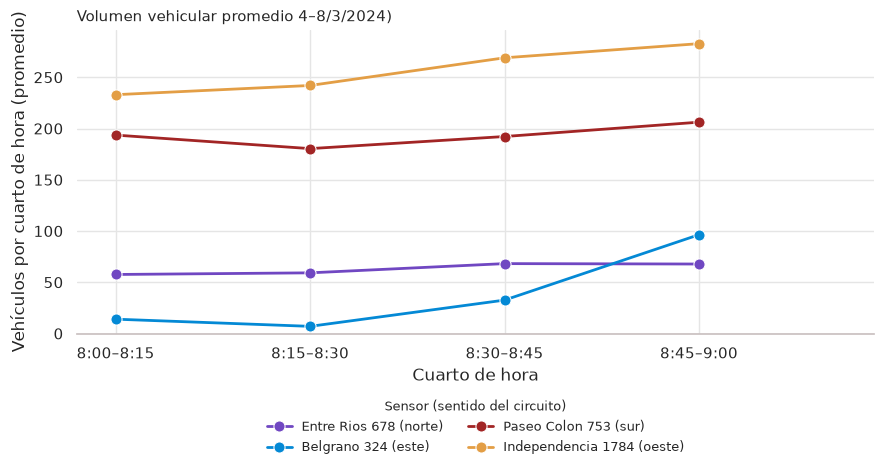

In [17]:
# etiquetas legibles
cuartos = {1: '8:00–8:15', 2: '8:15–8:30', 3: '8:30–8:45', 4: '8:45–9:00'}
prom_8am['cuarto'] = prom_8am['cuarto_hora_conteo'].map(cuartos)
prom_8am['sensor'] = (prom_8am['ubicacion_conteo'].str.replace(' AV.', '', regex=False).str.title()+ ' (' + prom_8am['sentido_circulacion_conteo'] + ')')

orden = ['Entre Rios 678 (norte)', 'Belgrano 324 (este)', 'Paseo Colon 753 (sur)', 'Independencia 1784 (oeste)']
colores = dict(zip(orden, ["#7047c2", "#0489d5", "#a22525", "#e39e45"]))

sns.set_theme(style='whitegrid', rc={'grid.color': '#e5e5e5', 'axes.edgecolor': "#cac1c1"})
fig, ax = plt.subplots(figsize=(9, 5))
sns.lineplot(data=prom_8am, x='cuarto', y='vehiculos_promedio', hue='sensor', hue_order=orden, palette=colores, marker='o', markersize=8, linewidth=2, sort=False, ax=ax)

for s in orden:
    y = prom_8am.loc[(prom_8am['cuarto_hora_conteo'] ==4), 'vehiculos_promedio'].iloc[0]

ax.set_title('Volumen vehicular promedio 4–8/3/2024)', loc='left', fontsize=11)
ax.set_xlabel('Cuarto de hora')
ax.set_ylabel('Vehículos por cuarto de hora (promedio)')
ax.set_ylim(0, None)
ax.set_xlim(-0.2, 3.9)
ax.legend(title='Sensor (sentido del circuito)', frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2, fontsize=9, title_fontsize=9)
sns.despine(left=True)
plt.tight_layout()
plt.show()